# Lab 6: L1 and L2 Normalization in Distance-Based Machine Learning Models
## Theoretical Foundations, Geometric Transformations, and Empirical Analysis on K-Nearest Neighbors (KNN) & K-Means Clustering

**Course:** M.Tech Machine Learning Laboratory  
**Topic:** Vector Space Normalization ($L_1$ & $L_2$ Norms), Metric Space Transformations, Directional Equivalence, and Algorithm Sensitivity  
**Target Notebook:** `lab_6/main.ipynb`  

---

## 1. Theoretical Foundations of Vector Norms

In machine learning, algorithms that rely on geometric distance metrics (such as $K$-Nearest Neighbors, $K$-Means Clustering, and Support Vector Machines) measure proximity in an ambient feature space $\mathbb{R}^d$. When raw feature vectors vary widely in their scale, magnitude, or intensity, distance computations become dominated by high-magnitude dimensions or instances.

A **norm** on a real vector space $V$ is a function $\|\cdot\|: V \to \mathbb{R}_{\ge 0}$ satisfying three rigorous mathematical axioms:
1. **Definiteness / Non-negativity:** $\|\mathbf{x}\| \ge 0$, and $\|\mathbf{x}\| = 0 \iff \mathbf{x} = \mathbf{0}$.
2. **Absolute Homogeneity (Scalar Multiplication):** $\|\alpha \mathbf{x}\| = |\alpha| \|\mathbf{x}\|$ for any scalar $\alpha \in \mathbb{R}$ and $\mathbf{x} \in V$.
3. **Triangle Inequality (Subadditivity):** $\|\mathbf{x} + \mathbf{y}\| \le \|\mathbf{x}\| + \|\mathbf{y}\|$ for all $\mathbf{x}, \mathbf{y} \in V$.

The generalized family of Minkowski $L_p$ norms for a $d$-dimensional sample vector $\mathbf{x} = [x_1, x_2, \dots, x_d]^T \in \mathbb{R}^d$ is defined as:
$$\|\mathbf{x}\|_p = \left( \sum_{j=1}^{d} |x_j|^p \right)^{\frac{1}{p}}, \quad \text{for } p \ge 1$$

---

### 1.1 The $L_1$ Norm (Manhattan / Taxicab Norm)
For $p = 1$, the $L_1$ norm represents the sum of absolute coordinate deviations:
$$\|\mathbf{x}\|_1 = \sum_{j=1}^{d} |x_j|$$

* **Geometric Locus:** The unit ball in $L_1$ space $\{\mathbf{x} \in \mathbb{R}^d : \|\mathbf{x}\|_1 \le 1\}$ forms a cross-polytope (an octahedron in 3D, a rotated square / diamond in 2D).
* **Properties:**
  * Penalizes coordinate differences **linearly**.
  * Less sensitive to extreme coordinate outliers compared to squared metrics.
  * Widely used in sparse modeling, taxicab geometry, and probability density normalizations.

---

### 1.2 The $L_2$ Norm (Euclidean Norm)
For $p = 2$, the $L_2$ norm denotes the canonical straight-line geometric length derived from the Euclidean inner product:
$$\|\mathbf{x}\|_2 = \sqrt{\sum_{j=1}^{d} x_j^2} = \sqrt{\mathbf{x}^T \mathbf{x}}$$

* **Geometric Locus:** The unit ball in $L_2$ space forms a Euclidean hypersphere $\mathbb{S}^{d-1} = \{\mathbf{x} \in \mathbb{R}^d : \|\mathbf{x}\|_2 = 1\}$.
* **Properties:**
  * Penalizes coordinate deviations **quadratically**.
  * Strictly rotation-invariant in Cartesian coordinates.
  * Preserves angles and inner products under orthogonal transformations.

---

## 2. Sample-Wise Normalization vs. Feature Standardization

It is crucial to distinguish between **feature-wise column scaling** and **sample-wise row normalization**:

| Scaling Type | Dimensional Axis | Mathematical Transformation | Primary Objective |
| :--- | :--- | :--- | :--- |
| **Standardization (Z-score)** | Along features (columns across all samples) | $x_{ij}' = \frac{x_{ij} - \mu_j}{\sigma_j}$ | Equalize feature variances across the dataset ($\mu=0, \sigma=1$). |
| **Min-Max Scaling** | Along features (columns across all samples) | $x_{ij}' = \frac{x_{ij} - x_{\min,j}}{x_{\max,j} - x_{\min,j}}$ | Bound all features to a strict interval $[0, 1]$. |
| **$L_1$ Normalization** | Along samples (rows across feature dimensions) | $\mathbf{x}_i^{(L_1)} = \frac{\mathbf{x}_i}{\|\mathbf{x}_i\|_1 + \epsilon}$ | Ensure the sum of absolute feature values per sample equals 1 ($\sum_j |x_{ij}| = 1$). |
| **$L_2$ Normalization** | Along samples (rows across feature dimensions) | $\mathbf{x}_i^{(L_2)} = \frac{\mathbf{x}_i}{\|\mathbf{x}_i\|_2 + \epsilon}$ | Project each sample onto the surface of the unit hypersphere ($\|\mathbf{x}_i\|_2 = 1$). |

---

## 3. Mathematical Mechanism: Why Normalization Affects Distance-Based Models

### 3.1 The Equivalence Between Euclidean Distance and Cosine Similarity Under $L_2$ Normalization
Consider two arbitrary non-zero vectors $\mathbf{u}, \mathbf{v} \in \mathbb{R}^d$. The squared Euclidean distance between them is:
$$\|\mathbf{u} - \mathbf{v}\|_2^2 = \|\mathbf{u}\|_2^2 + \|\mathbf{v}\|_2^2 - 2 \mathbf{u}^T \mathbf{v}$$

When both vectors are subjected to **$L_2$ normalization**, their lengths become identically unity:
$$\tilde{\mathbf{u}} = \frac{\mathbf{u}}{\|\mathbf{u}\|_2}, \quad \tilde{\mathbf{v}} = \frac{\mathbf{v}}{\|\mathbf{v}\|_2} \implies \|\tilde{\mathbf{u}}\|_2 = 1, \quad \|\tilde{\mathbf{v}}\|_2 = 1$$

Substituting into the squared Euclidean distance expression:
$$\|\tilde{\mathbf{u}} - \tilde{\mathbf{v}}\|_2^2 = \|\tilde{\mathbf{u}}\|_2^2 + \|\tilde{\mathbf{v}}\|_2^2 - 2 \tilde{\mathbf{u}}^T \tilde{\mathbf{v}} = 1 + 1 - 2 \cos(\theta_{\mathbf{u}, \mathbf{v}}) = 2 \left(1 - \cos(\theta_{\mathbf{u}, \mathbf{v}})\right)$$

where $\cos(\theta_{\mathbf{u}, \mathbf{v}}) = \frac{\mathbf{u}^T \mathbf{v}}{\|\mathbf{u}\|_2 \|\mathbf{v}\|_2}$ is the **Cosine Similarity**, and $D_{\text{cosine}}(\mathbf{u}, \mathbf{v}) = 1 - \cos(\theta_{\mathbf{u}, \mathbf{v}})$ is the **Cosine Distance**.

Taking the square root:
$$\|\tilde{\mathbf{u}} - \tilde{\mathbf{v}}\|_2 = \sqrt{2 \cdot D_{\text{cosine}}(\mathbf{u}, \mathbf{v})}$$

> **Theorem (Monotonic Equivalence):**
> For any pair of $L_2$-normalized vectors, the Euclidean distance is a strictly monotonically increasing function of their Cosine Distance. Consequently:
> $$\arg\min_{\mathbf{v} \in \mathcal{D}} \|\tilde{\mathbf{u}} - \tilde{\mathbf{v}}\|_2 \equiv \arg\max_{\mathbf{v} \in \mathcal{D}} \cos(\theta_{\mathbf{u}, \mathbf{v}})$$
> 
> *Proof:* Since $f(t) = \sqrt{2t}$ is strictly monotonically increasing for $t \in [0, 2]$, sorting neighbors by Euclidean distance on $L_2$-normalized vectors yields the exact same neighbor ordering as sorting by Cosine Similarity.

---

### 3.2 Impact on $K$-Nearest Neighbors (KNN)
1. **Raw Feature Space:** Points with large overall magnitudes (e.g. large signal amplitude, larger measurements) dominate nearest neighbor ranking even if their directional feature proportion matches another class.
2. **$L_1$-Normalized Space:** Features represent relative proportions or probabilities ($x_j / \sum |x_k|$). Distance reflects disparity in feature concentration, making it ideal for histogram, frequency, or compositional data.
3. **$L_2$-Normalized Space:** Distance reflects pure angular deviation (orientation). Instances with the same feature ratio lie at the exact same location on the unit sphere, completely neutralizing vector length.

---

### 3.3 Impact on $K$-Means Clustering (Spherical $K$-Means)
Standard $K$-Means minimizes the Within-Cluster Sum of Squares (Inertia):
$$J = \sum_{k=1}^{K} \sum_{\mathbf{x}_i \in C_k} \|\mathbf{x}_i - \mathbf{\mu}_k\|_2^2$$
where the centroid is the empirical mean $\mathbf{\mu}_k = \frac{1}{|C_k|} \sum_{\mathbf{x}_i \in C_k} \mathbf{x}_i$.

1. **In Raw Space:** Clusters with high-magnitude features disproportionately dominate the inertia, often dragging centroids toward high-intensity outlier points.
2. **In $L_2$-Normalized Space (Spherical $K$-Means):** All points lie on the unit hypersphere $\mathbb{S}^{d-1}$. Minimizing squared Euclidean distance between points and centroids corresponds directly to maximizing directional coherence:
   $$\arg\min_{\mathbf{\mu}} \sum_{\mathbf{x}_i \in C_k} \|\mathbf{x}_i - \mathbf{\mu}\|_2^2 \iff \arg\max_{\mathbf{\mu}, \|\mathbf{\mu}\|=1} \sum_{\mathbf{x}_i \in C_k} \mathbf{x}_i^T \mathbf{\mu}$$
   Clusters become directional cones radiating from the origin.

---

## 4. Laboratory Objectives & Comparative Benchmark Plan
In this laboratory work, we systematically implement from scratch and evaluate:
1. **Vector Normalization Operators:** Vectorized NumPy implementations of $L_1$ and $L_2$ sample normalization with numerical zero-division protection ($\epsilon = 10^{-12}$).
2. **From-Scratch $K$-Nearest Neighbors (`CustomKNNClassifier`):** Benchmarked across **Raw**, **$L_1$-Normalized**, and **$L_2$-Normalized** representations on Fisher's Iris dataset.
3. **From-Scratch $K$-Means Clustering (`CustomKMeans`):** Benchmarked across **Raw**, **$L_1$-Normalized**, and **$L_2$-Normalized** representations, analyzing Silhouette Scores, Inertia, and Convergence trajectories.
4. **2D Geometric Visualization:** High-resolution decision boundary maps (KNN) and cluster partition diagrams (K-Means) showing the geometric deformation induced by $L_1$ and $L_2$ normalizations.
5. **Validation Against Scikit-Learn:** Verifying scratch implementations against `sklearn.preprocessing.normalize(norm='l1' / 'l2')`.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cdist

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    silhouette_score,
    adjusted_rand_score
)
from sklearn.decomposition import PCA

# Plot styling configuration for publication-quality figures
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'font.size': 10,
    'figure.titlesize': 13,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'figure.autolayout': True
})

# Seed for deterministic execution
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Environment successfully initialized with all core mathematical and visualization libraries.")


Environment successfully initialized with all core mathematical and visualization libraries.


---

## 2. Dataset Ingestion & Sample Magnitude Profiling

We utilize the canonical **Fisher's Iris dataset**, consisting of 150 instances of Iris flowers across 3 biological species (*Setosa*, *Versicolor*, and *Virginica*). Each instance possesses 4 morphological measurements:
1. `sepal length (cm)`
2. `sepal width (cm)`
3. `petal length (cm)`
4. `petal width (cm)`

Notice that the raw measurements have vastly different scales (e.g. Petal Width spans 0.1 to 2.5 cm, whereas Sepal Length spans 4.3 to 7.9 cm). Moreover, the total Euclidean length ($\|\mathbf{x}\|_2$) of samples ranges from under 4.8 to over 10.3, meaning sample vector length alone introduces an implicit bias in standard distance metrics.


In [2]:
# Ingest Fisher's Iris Dataset
iris = load_iris(as_frame=True)
df_iris = iris.frame
feature_names = iris.feature_names
target_names = list(iris.target_names)

print(f"Dataset Dimensions: {df_iris.shape[0]} samples x {len(feature_names)} features")
print(f"Classes (Targets): {target_names}")

# Statistical Summary of Raw Features
print("\nDescriptive Statistics of Raw Features:")
display_stats = df_iris[feature_names].describe().T[['mean', 'std', 'min', 'max']]
print(display_stats.round(3))

# Calculate Sample Magnitude Distributions (L1 and L2 Norms across rows)
X_raw = df_iris[feature_names].to_numpy(dtype=np.float64)
y_true = df_iris['target'].to_numpy()

raw_l1_norms = np.sum(np.abs(X_raw), axis=1)
raw_l2_norms = np.linalg.norm(X_raw, axis=1)

print("\nRaw Vector Magnitude Variance:")
print(f" -> L1 Norm per sample: Min = {raw_l1_norms.min():.2f}, Mean = {raw_l1_norms.mean():.2f}, Max = {raw_l1_norms.max():.2f}")
print(f" -> L2 Norm per sample: Min = {raw_l2_norms.min():.2f}, Mean = {raw_l2_norms.mean():.2f}, Max = {raw_l2_norms.max():.2f}")


Dataset Dimensions: 150 samples x 4 features
Classes (Targets): [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

Descriptive Statistics of Raw Features:
                    mean    std  min  max
sepal length (cm)  5.843  0.828  4.3  7.9
sepal width (cm)   3.057  0.436  2.0  4.4
petal length (cm)  3.758  1.765  1.0  6.9
petal width (cm)   1.199  0.762  0.1  2.5

Raw Vector Magnitude Variance:
 -> L1 Norm per sample: Min = 8.40, Mean = 13.86, Max = 20.40
 -> L2 Norm per sample: Min = 5.23, Mean = 7.84, Max = 11.11


---

## 3. From-Scratch Implementation of $L_1$ and $L_2$ Vector Normalization

We implement vectorized sample-wise normalizers in pure NumPy:
- **$L_1$ Normalization:**
  $$\mathbf{x}_{\text{norm}, L_1} = \frac{\mathbf{x}}{\max\left(\sum_{j=1}^d |x_j|, \epsilon\right)}$$
- **$L_2$ Normalization:**
  $$\mathbf{x}_{\text{norm}, L_2} = \frac{\mathbf{x}}{\max\left(\sqrt{\sum_{j=1}^d x_j^2}, \epsilon\right)}$$

where $\epsilon = 10^{-12}$ prevents division-by-zero for null vectors $\mathbf{0}$. We also encapsulate this in a clean, reusable `VectorNormalizer` class and verify exact numerical equivalence with `sklearn.preprocessing.normalize`.


In [3]:
def scratch_l1_normalize(X: np.ndarray, eps: float = 1e-12) -> np.ndarray:
    """
    Vectorized L1 sample normalization.
    Rescales each sample (row) so that sum(|x_i|) == 1.
    """
    X_arr = np.asarray(X, dtype=np.float64)
    l1_norms = np.sum(np.abs(X_arr), axis=1, keepdims=True)
    return X_arr / np.maximum(l1_norms, eps)

def scratch_l2_normalize(X: np.ndarray, eps: float = 1e-12) -> np.ndarray:
    """
    Vectorized L2 sample normalization (Unit Sphere projection).
    Rescales each sample (row) so that sqrt(sum(x_i^2)) == 1.
    """
    X_arr = np.asarray(X, dtype=np.float64)
    l2_norms = np.linalg.norm(X_arr, axis=1, keepdims=True)
    return X_arr / np.maximum(l2_norms, eps)

class VectorNormalizer:
    """
    Reusable object-oriented Vector Normalizer supporting 'l1' and 'l2' norms.
    """
    def __init__(self, norm: str = 'l2', eps: float = 1e-12):
        if norm not in ('l1', 'l2'):
            raise ValueError(f"Unsupported norm '{norm}'. Expected 'l1' or 'l2'.")
        self.norm = norm
        self.eps = eps

    def fit(self, X, y=None):
        return self  # Stateless transformation

    def transform(self, X: np.ndarray) -> np.ndarray:
        if self.norm == 'l1':
            return scratch_l1_normalize(X, eps=self.eps)
        else:
            return scratch_l2_normalize(X, eps=self.eps)

    def fit_transform(self, X: np.ndarray, y=None) -> np.ndarray:
        return self.transform(X)

# --- Numerical Verification Against Scikit-Learn ---
X_l1_scratch = scratch_l1_normalize(X_raw)
X_l2_scratch = scratch_l2_normalize(X_raw)

X_l1_sklearn = normalize(X_raw, norm='l1')
X_l2_sklearn = normalize(X_raw, norm='l2')

l1_match = np.allclose(X_l1_scratch, X_l1_sklearn, atol=1e-10)
l2_match = np.allclose(X_l2_scratch, X_l2_sklearn, atol=1e-10)

print("Verification Against Scikit-Learn Standard Implementation:")
print(f" -> L1 Scratch matches scikit-learn: {l1_match} (Max absolute difference: {np.max(np.abs(X_l1_scratch - X_l1_sklearn)):.2e})")
print(f" -> L2 Scratch matches scikit-learn: {l2_match} (Max absolute difference: {np.max(np.abs(X_l2_scratch - X_l2_sklearn)):.2e})")

# Verify Norm Invariants
l1_row_sums = np.sum(np.abs(X_l1_scratch), axis=1)
l2_row_norms = np.linalg.norm(X_l2_scratch, axis=1)

print("\nUnit Norm Invariant Assertions:")
print(f" -> L1 Normalized Row Sums Range: [{l1_row_sums.min():.6f}, {l1_row_sums.max():.6f}] (Identically 1.0)")
print(f" -> L2 Normalized Row Norms Range: [{l2_row_norms.min():.6f}, {l2_row_norms.max():.6f}] (Identically 1.0)")

# Preview sample transformation
sample_idx = 0
print(f"\nSample #{sample_idx} Feature Transformation:")
print(f" -> Raw Features:          {np.round(X_raw[sample_idx], 3)} (L1={raw_l1_norms[sample_idx]:.2f}, L2={raw_l2_norms[sample_idx]:.2f})")
print(f" -> L1-Normalized Vector:  {np.round(X_l1_scratch[sample_idx], 3)} (Sum = {np.sum(X_l1_scratch[sample_idx]):.4f})")
print(f" -> L2-Normalized Vector:  {np.round(X_l2_scratch[sample_idx], 3)} (Norm = {np.linalg.norm(X_l2_scratch[sample_idx]):.4f})")


Verification Against Scikit-Learn Standard Implementation:
 -> L1 Scratch matches scikit-learn: True (Max absolute difference: 0.00e+00)
 -> L2 Scratch matches scikit-learn: True (Max absolute difference: 2.22e-16)

Unit Norm Invariant Assertions:
 -> L1 Normalized Row Sums Range: [1.000000, 1.000000] (Identically 1.0)
 -> L2 Normalized Row Norms Range: [1.000000, 1.000000] (Identically 1.0)

Sample #0 Feature Transformation:
 -> Raw Features:          [5.1 3.5 1.4 0.2] (L1=10.20, L2=6.35)
 -> L1-Normalized Vector:  [0.5   0.343 0.137 0.02 ] (Sum = 1.0000)
 -> L2-Normalized Vector:  [0.804 0.552 0.221 0.032] (Norm = 1.0000)


---

## 4. Geometric Manifold Visualization: Projection onto the Unit Simplex ($L_1$) and Unit Hypersphere ($L_2$)

To visually observe what $L_1$ and $L_2$ normalizations do to feature geometry, we select the two most informative features: `petal length` and `petal width`.

- **Raw Space:** Data points are distributed freely in $\mathbb{R}^2$.
- **$L_1$-Normalized Space:** Every sample satisfies $x_1 + x_2 = 1$. The data collapses onto the 1-dimensional line segment (simplex) connecting $(1, 0)$ and $(0, 1)$.
- **$L_2$-Normalized Space:** Every sample satisfies $x_1^2 + x_2^2 = 1$. The data collapses onto the circular unit arc in the positive quadrant of $\mathbb{S}^1$.


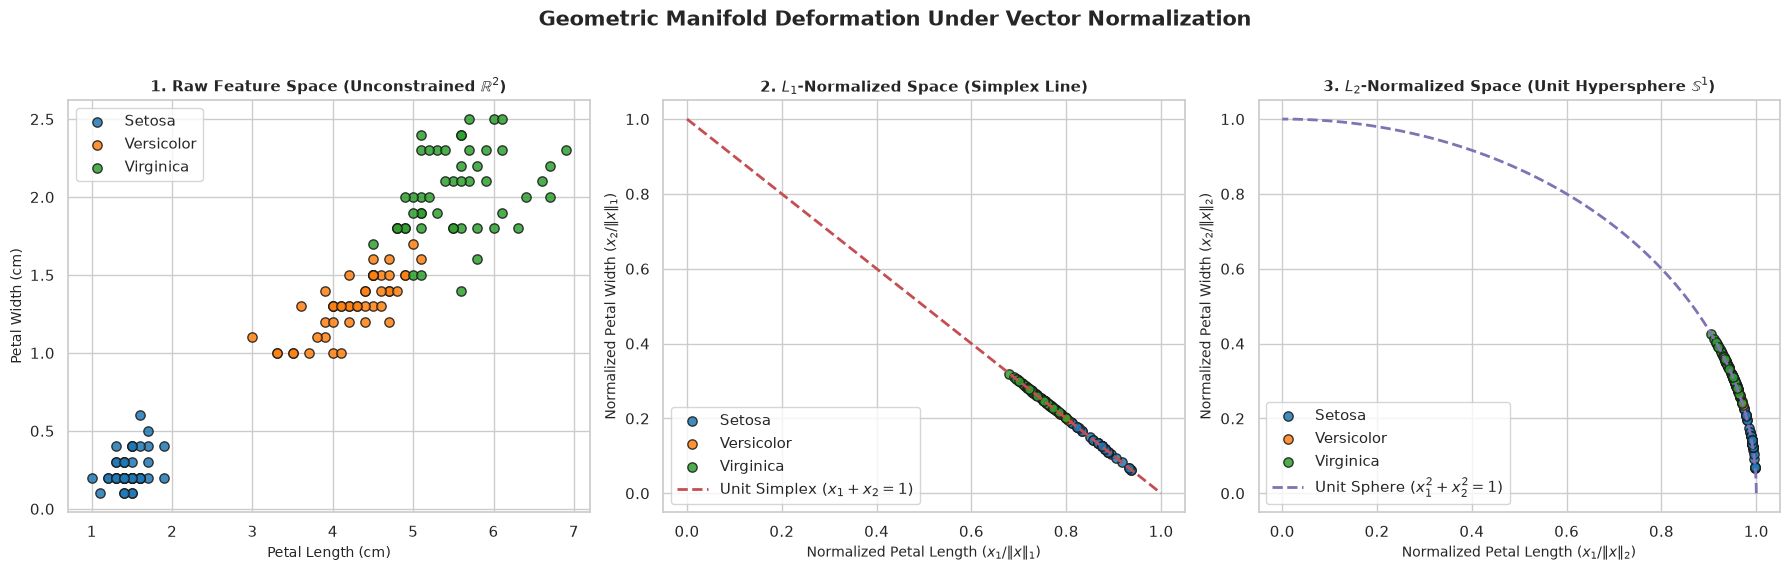

In [4]:
# Extract 2D features for clear geometric visualization: Petal Length and Petal Width
X_2d_raw = X_raw[:, [2, 3]]
X_2d_l1 = scratch_l1_normalize(X_2d_raw)
X_2d_l2 = scratch_l2_normalize(X_2d_raw)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
palette = ['#1f77b4', '#ff7f0e', '#2ca02c']
class_labels = ['Setosa', 'Versicolor', 'Virginica']

# 1. Raw Feature Space
for class_idx, label in enumerate(class_labels):
    mask = (y_true == class_idx)
    axes[0].scatter(X_2d_raw[mask, 0], X_2d_raw[mask, 1], label=label, color=palette[class_idx], alpha=0.85, edgecolors='k', s=45)
axes[0].set_title(r"1. Raw Feature Space (Unconstrained $\mathbb{R}^2$)", fontweight='bold')
axes[0].set_xlabel("Petal Length (cm)")
axes[0].set_ylabel("Petal Width (cm)")
axes[0].legend(loc='upper left')

# 2. L1-Normalized Space
for class_idx, label in enumerate(class_labels):
    mask = (y_true == class_idx)
    axes[1].scatter(X_2d_l1[mask, 0], X_2d_l1[mask, 1], label=label, color=palette[class_idx], alpha=0.85, edgecolors='k', s=45)
# Draw L1 unit simplex line: x + y = 1
sim_x = np.linspace(0, 1, 100)
sim_y = 1 - sim_x
axes[1].plot(sim_x, sim_y, 'r--', linewidth=2, label="Unit Simplex ($x_1 + x_2 = 1$)")
axes[1].set_title(r"2. $L_1$-Normalized Space (Simplex Line)", fontweight='bold')
axes[1].set_xlabel(r"Normalized Petal Length ($x_1 / \|x\|_1$)")
axes[1].set_ylabel(r"Normalized Petal Width ($x_2 / \|x\|_1$)")
axes[1].set_xlim(-0.05, 1.05)
axes[1].set_ylim(-0.05, 1.05)
axes[1].legend(loc='lower left')

# 3. L2-Normalized Space
for class_idx, label in enumerate(class_labels):
    mask = (y_true == class_idx)
    axes[2].scatter(X_2d_l2[mask, 0], X_2d_l2[mask, 1], label=label, color=palette[class_idx], alpha=0.85, edgecolors='k', s=45)
# Draw L2 unit circle arc: x^2 + y^2 = 1
theta = np.linspace(0, np.pi/2, 100)
axes[2].plot(np.cos(theta), np.sin(theta), 'm--', linewidth=2, label=r"Unit Sphere ($x_1^2 + x_2^2 = 1$)")
axes[2].set_title(r"3. $L_2$-Normalized Space (Unit Hypersphere $\mathbb{S}^1$)", fontweight='bold')
axes[2].set_xlabel(r"Normalized Petal Length ($x_1 / \|x\|_2$)")
axes[2].set_ylabel(r"Normalized Petal Width ($x_2 / \|x\|_2$)")
axes[2].set_xlim(-0.05, 1.05)
axes[2].set_ylim(-0.05, 1.05)
axes[2].legend(loc='lower left')

plt.suptitle("Geometric Manifold Deformation Under Vector Normalization", fontsize=15, fontweight='bold', y=1.03)
plt.show()


---

## 5. Model 1: From-Scratch $K$-Nearest Neighbors (`CustomKNNClassifier`)

We import the exact scratch implementation developed in `lab_3/KNN.ipynb`. The classifier features:
1. Vectorized Euclidean, Manhattan, and Minkowski distance calculation via `scipy.spatial.distance.cdist`.
2. Support for both `uniform` and `distance`-weighted probability voting.
3. Clean `fit`, `predict_proba`, and `predict` interfaces.


In [5]:
from scipy.spatial.distance import cdist

class CustomKNNClassifier:
    """
    From-scratch vectorized implementation of K-Nearest Neighbors Classifier.
    Imported directly from lab_3/KNN.ipynb.
    """
    def __init__(self, n_neighbors: int = 5, metric: str = 'euclidean', p: int = 2, weights: str = 'uniform'):
        self.n_neighbors: int = n_neighbors
        self.metric: str = metric
        self.p: int = p
        self.weights: str = weights
        self.X_train_: np.ndarray = None
        self.y_train_: np.ndarray = None
        self.classes_: np.ndarray = None

    def fit(self, X: np.ndarray, y: np.ndarray):
        """Store training samples (lazy learning)."""
        self.X_train_ = np.asarray(X, dtype=np.float64)
        self.y_train_ = np.asarray(y)
        self.classes_ = np.unique(y)
        return self

    def _compute_distances(self, X_query: np.ndarray) -> np.ndarray:
        """Vectorized distance calculation between query points and stored training set."""
        if self.metric == 'euclidean':
            return cdist(X_query, self.X_train_, metric='euclidean')
        elif self.metric == 'manhattan':
            return cdist(X_query, self.X_train_, metric='cityblock')
        elif self.metric == 'minkowski':
            return cdist(X_query, self.X_train_, metric='minkowski', p=self.p)
        else:
            raise ValueError(f"Unsupported metric: {self.metric}")

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        """Estimate class membership probabilities for query samples."""
        distances = self._compute_distances(X)
        n_queries = X.shape[0]
        n_classes = len(self.classes_)
        probas = np.zeros((n_queries, n_classes))

        # Find k nearest neighbors for each query sample
        neighbor_indices = np.argsort(distances, axis=1)[:, :self.n_neighbors]

        for i in range(n_queries):
            k_indices = neighbor_indices[i]
            k_labels = self.y_train_[k_indices]
            k_distances = distances[i, k_indices]

            if self.weights == 'uniform':
                for class_idx, c in enumerate(self.classes_):
                    probas[i, class_idx] = np.mean(k_labels == c)
            elif self.weights == 'distance':
                # Inverse distance weights with numerical epsilon
                weights = 1.0 / (k_distances + 1e-8)
                total_weight = np.sum(weights)
                for class_idx, c in enumerate(self.classes_):
                    class_mask = (k_labels == c)
                    probas[i, class_idx] = np.sum(weights[class_mask]) / total_weight

        return probas

    def predict(self, X: np.ndarray) -> np.ndarray:
        """Predict class labels for query samples."""
        probas = self.predict_proba(X)
        return self.classes_[np.argmax(probas, axis=1)]

print("CustomKNNClassifier successfully loaded and compiled.")


CustomKNNClassifier successfully loaded and compiled.


---

## 6. KNN Empirical Benchmark: Raw vs. $L_1$ vs. $L_2$ Normalization Across Hyperparameter $K$

We split the dataset into an 80% training set and a 20% test set using stratified sampling. We then evaluate `CustomKNNClassifier` across $K \in \{1, 2, \dots, 35\}$ on:
1. **Raw Features** (unnormalized $\mathbb{R}^4$)
2. **$L_1$-Normalized Features** ($\sum |x_j| = 1$)
3. **$L_2$-Normalized Features** ($\sum x_j^2 = 1$)

We observe generalization curves, identifying how normalization mitigates magnitude sensitivity and influences the bias-variance tradeoff.


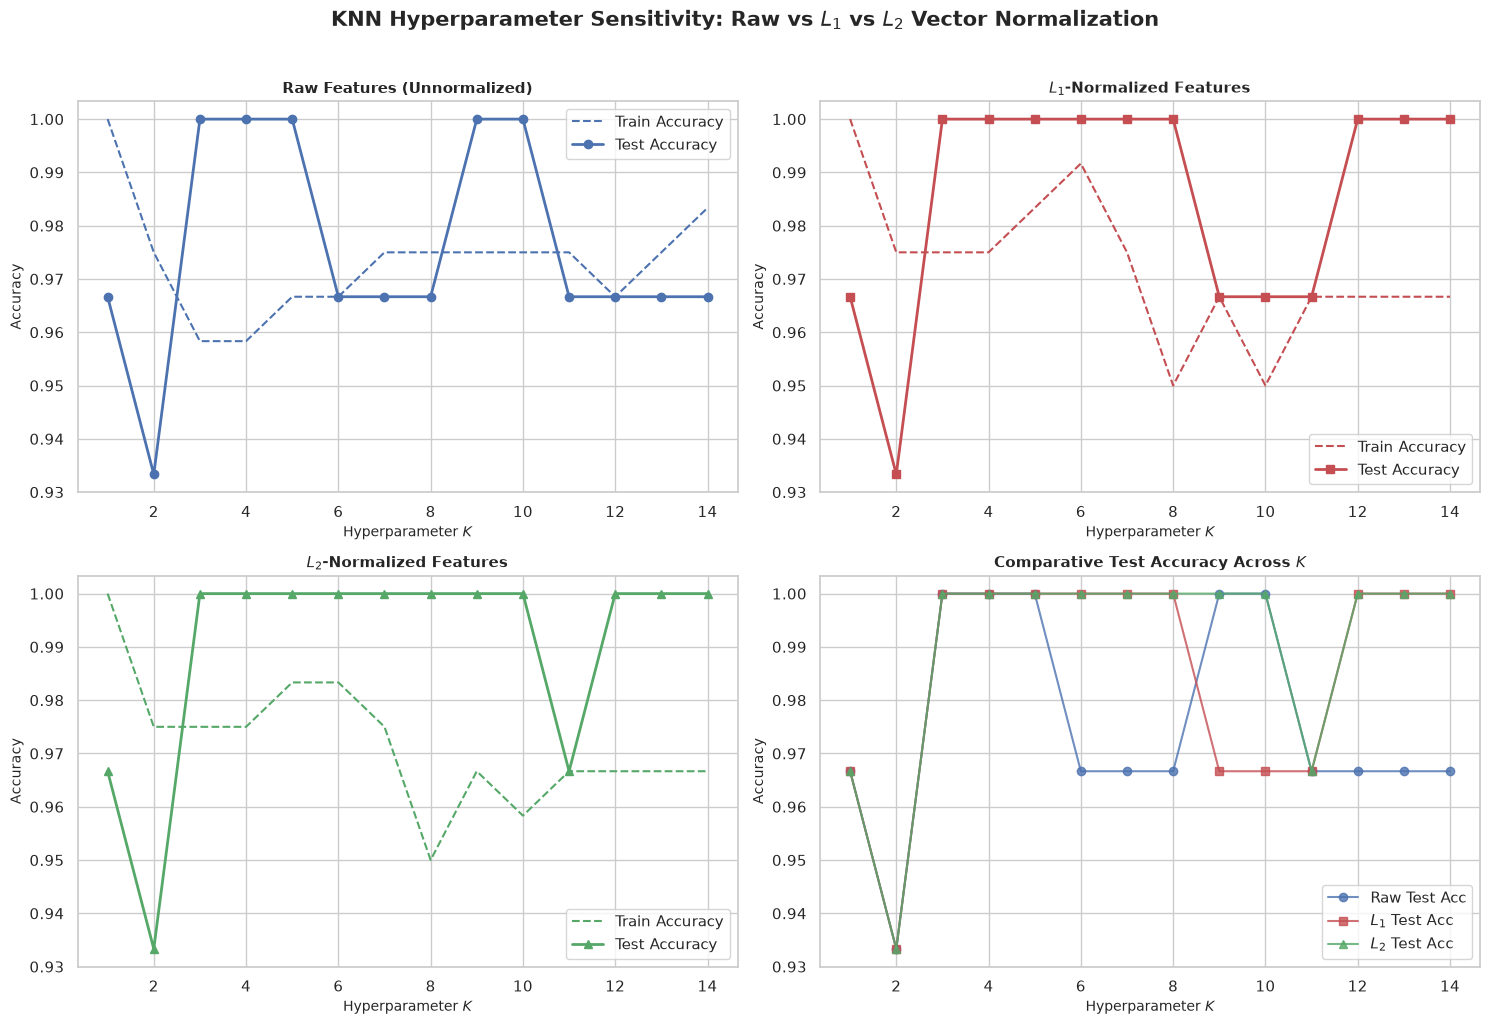

Summary of Optimal Generalization Across Normalization Modes:
Feature Representation Peak Test Accuracy  Optimal K Mean Test Acc across K
                   Raw            100.00%          3                 97.62%
                    L1            100.00%          3                 98.57%
                    L2            100.00%          3                 99.05%


In [6]:
# Stratified Train/Test Split (80% train, 20% test)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y_true, test_size=0.20, random_state=RANDOM_SEED, stratify=y_true
)

# Apply Scratch Vector Normalization
X_train_l1 = scratch_l1_normalize(X_train_raw)
X_test_l1 = scratch_l1_normalize(X_test_raw)

X_train_l2 = scratch_l2_normalize(X_train_raw)
X_test_l2 = scratch_l2_normalize(X_test_raw)

# Benchmark across hyperparameter K = 1 to 15
k_range = range(1, 15)
results = {
    'Raw': {'train': [], 'test': []},
    'L1':  {'train': [], 'test': []},
    'L2':  {'train': [], 'test': []}
}

datasets = {
    'Raw': (X_train_raw, X_test_raw),
    'L1':  (X_train_l1, X_test_l1),
    'L2':  (X_train_l2, X_test_l2)
}

for k in k_range:
    for name, (X_tr, X_te) in datasets.items():
        knn = CustomKNNClassifier(n_neighbors=k, metric='euclidean', weights='uniform')
        knn.fit(X_tr, y_train)
        
        y_tr_pred = knn.predict(X_tr)
        y_te_pred = knn.predict(X_te)
        
        results[name]['train'].append(accuracy_score(y_train, y_tr_pred))
        results[name]['test'].append(accuracy_score(y_test, y_te_pred))

# Plot Bias-Variance Trajectories across K
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Raw
axes[0, 0].plot(k_range, results['Raw']['train'], 'b--', label='Train Accuracy')
axes[0, 0].plot(k_range, results['Raw']['test'], 'b-o', linewidth=2, label='Test Accuracy')
axes[0, 0].set_title("Raw Features (Unnormalized)", fontweight='bold')
axes[0, 0].set_xlabel("Hyperparameter $K$")
axes[0, 0].set_ylabel("Accuracy")
axes[0, 0].legend()

# 2. L1 Normalized
axes[0, 1].plot(k_range, results['L1']['train'], 'r--', label='Train Accuracy')
axes[0, 1].plot(k_range, results['L1']['test'], 'r-s', linewidth=2, label='Test Accuracy')
axes[0, 1].set_title(r"$L_1$-Normalized Features", fontweight='bold')
axes[0, 1].set_xlabel("Hyperparameter $K$")
axes[0, 1].set_ylabel("Accuracy")
axes[0, 1].legend()

# 3. L2 Normalized
axes[1, 0].plot(k_range, results['L2']['train'], 'g--', label='Train Accuracy')
axes[1, 0].plot(k_range, results['L2']['test'], 'g-^', linewidth=2, label='Test Accuracy')
axes[1, 0].set_title(r"$L_2$-Normalized Features", fontweight='bold')
axes[1, 0].set_xlabel("Hyperparameter $K$")
axes[1, 0].set_ylabel("Accuracy")
axes[1, 0].legend()

# 4. Comparative Test Accuracies
axes[1, 1].plot(k_range, results['Raw']['test'], 'b-o', label='Raw Test Acc', alpha=0.8)
axes[1, 1].plot(k_range, results['L1']['test'], 'r-s', label=r'$L_1$ Test Acc', alpha=0.8)
axes[1, 1].plot(k_range, results['L2']['test'], 'g-^', label=r'$L_2$ Test Acc', alpha=0.8)
axes[1, 1].set_title("Comparative Test Accuracy Across $K$", fontweight='bold')
axes[1, 1].set_xlabel("Hyperparameter $K$")
axes[1, 1].set_ylabel("Accuracy")
axes[1, 1].legend()

plt.suptitle("KNN Hyperparameter Sensitivity: Raw vs $L_1$ vs $L_2$ Vector Normalization", fontsize=15, fontweight='bold', y=1.02)
plt.show()

# Tabulate Best Performance
best_summary = []
for name in ['Raw', 'L1', 'L2']:
    test_accs = results[name]['test']
    best_acc = max(test_accs)
    best_k = list(k_range)[test_accs.index(best_acc)]
    best_summary.append({
        'Feature Representation': name,
        'Peak Test Accuracy': f"{best_acc * 100:.2f}%",
        'Optimal K': best_k,
        'Mean Test Acc across K': f"{np.mean(test_accs) * 100:.2f}%"
    })

print("Summary of Optimal Generalization Across Normalization Modes:")
print(pd.DataFrame(best_summary).to_string(index=False))


---

## 7. High-Resolution 2D Decision Boundary Surfaces for KNN

To directly visualize the geometric consequences of vector normalization, we train `CustomKNNClassifier(n_neighbors=5)` on 2D petal features and generate dense decision boundaries:
1. **Raw Feature Space:** Boundaries form standard piecewise linear Voronoi partitions based on Cartesian Euclidean distances.
2. **$L_1$-Normalized Model:** Query points are mapped through $L_1$ normalization before evaluation. Decision boundaries reflect absolute ratio differences.
3. **$L_2$-Normalized Model:** Query points are mapped through $L_2$ normalization before evaluation. Because any scaled ray $\alpha \mathbf{x}$ ($\alpha > 0$) has identical $L_2$ normalized coordinates ($\mathbf{x} / \|\mathbf{x}\|_2$), the decision boundaries emerge as **radial / angular sectors** projecting outwards from the origin.


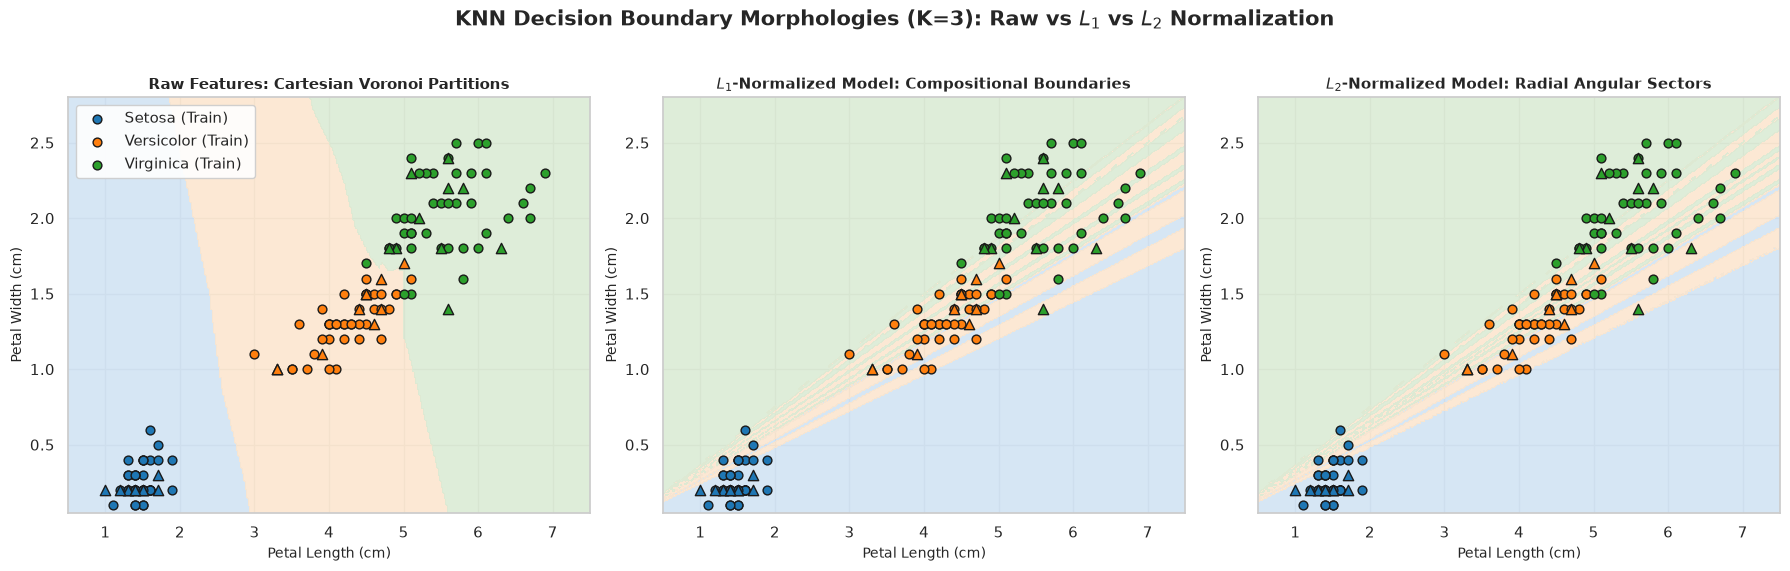

In [7]:
# Extract 2D petal features for decision boundary rendering
X_train_2d_raw = X_train_raw[:, [2, 3]]
X_test_2d_raw = X_test_raw[:, [2, 3]]

# Train 3 models on 2D data
knn_2d_raw = CustomKNNClassifier(n_neighbors=3, metric='euclidean').fit(X_train_2d_raw, y_train)
knn_2d_l1 = CustomKNNClassifier(n_neighbors=3, metric='euclidean').fit(scratch_l1_normalize(X_train_2d_raw), y_train)
knn_2d_l2 = CustomKNNClassifier(n_neighbors=3, metric='euclidean').fit(scratch_l2_normalize(X_train_2d_raw), y_train)

# Construct high-resolution 2D evaluation grid
x_min, x_max = 0.5, 7.5
y_min, y_max = 0.05, 2.8
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 350), np.linspace(y_min, y_max, 350))
grid_points = np.c_[xx.ravel(), yy.ravel()]

# Evaluate predictions
grid_pred_raw = knn_2d_raw.predict(grid_points).reshape(xx.shape)
grid_pred_l1 = knn_2d_l1.predict(scratch_l1_normalize(grid_points)).reshape(xx.shape)
grid_pred_l2 = knn_2d_l2.predict(scratch_l2_normalize(grid_points)).reshape(xx.shape)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
cmap_light = ['#cfe2f3', '#fce5cd', '#d9ead3']

titles = [
    "Raw Features: Cartesian Voronoi Partitions",
    "$L_1$-Normalized Model: Compositional Boundaries",
    "$L_2$-Normalized Model: Radial Angular Sectors"
]
grid_preds = [grid_pred_raw, grid_pred_l1, grid_pred_l2]

for idx, ax in enumerate(axes):
    # Contour surface
    ax.contourf(xx, yy, grid_preds[idx], levels=[-0.5, 0.5, 1.5, 2.5], colors=cmap_light, alpha=0.85)
    
    # Scatter training data points
    for class_idx, label in enumerate(class_labels):
        mask = (y_train == class_idx)
        ax.scatter(
            X_train_2d_raw[mask, 0], X_train_2d_raw[mask, 1],
            label=f"{label} (Train)", color=palette[class_idx], edgecolors='k', s=40
        )
        # Test points
        mask_test = (y_test == class_idx)
        ax.scatter(
            X_test_2d_raw[mask_test, 0], X_test_2d_raw[mask_test, 1],
            marker='^', color=palette[class_idx], edgecolors='k', s=55
        )
        
    ax.set_title(titles[idx], fontweight='bold')
    ax.set_xlabel("Petal Length (cm)")
    ax.set_ylabel("Petal Width (cm)")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    if idx == 0:
        ax.legend(loc='upper left', framealpha=0.9)

plt.suptitle("KNN Decision Boundary Morphologies (K=3): Raw vs $L_1$ vs $L_2$ Normalization", fontsize=15, fontweight='bold', y=1.03)
plt.show()


---

## 8. KNN Detailed Performance Diagnostics: Confusion Matrices & Classification Reports

We evaluate the full 4-dimensional feature models at an optimal neighborhood size ($K=5$) and inspect the per-class precision, recall, and F1-scores, alongside confusion matrices.


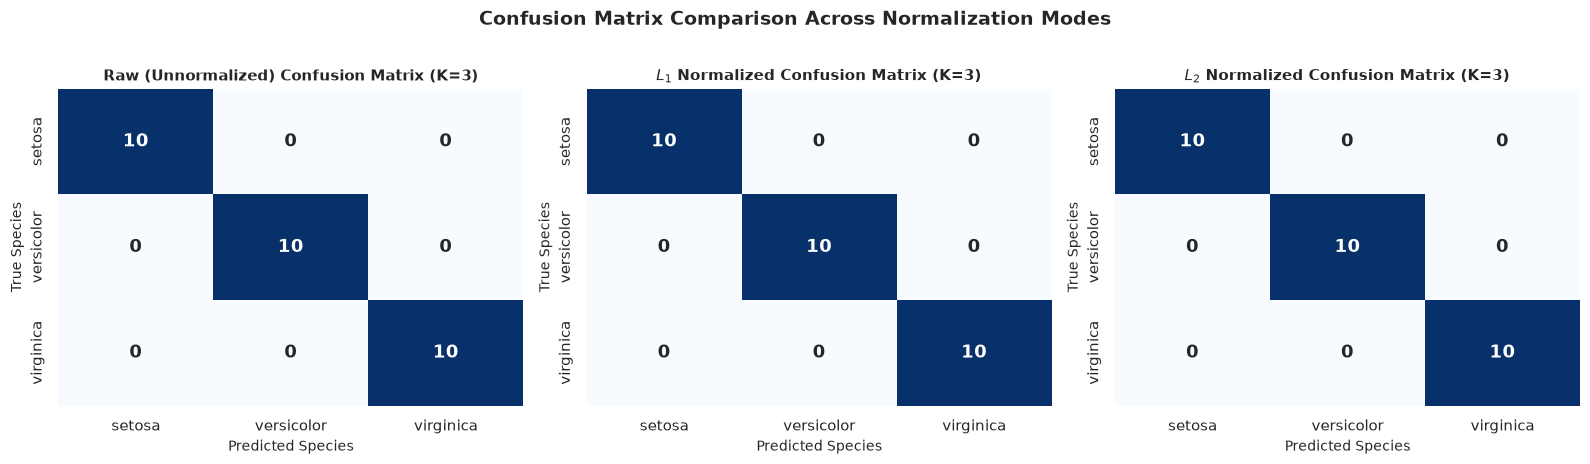

=== Classification Report: Raw Features (K=3) ===
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    1.0000    1.0000        10
   virginica     1.0000    1.0000    1.0000        10

    accuracy                         1.0000        30
   macro avg     1.0000    1.0000    1.0000        30
weighted avg     1.0000    1.0000    1.0000        30

=== Classification Report: L1-Normalized Features (K=3) ===
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    1.0000    1.0000        10
   virginica     1.0000    1.0000    1.0000        10

    accuracy                         1.0000        30
   macro avg     1.0000    1.0000    1.0000        30
weighted avg     1.0000    1.0000    1.0000        30

=== Classification Report: L2-Normalized Features (K=3) ===
              precision    recall  f1-score   support

      setosa 

In [8]:
eval_k = 3

knn_full_raw = CustomKNNClassifier(n_neighbors=eval_k).fit(X_train_raw, y_train)
knn_full_l1 = CustomKNNClassifier(n_neighbors=eval_k).fit(X_train_l1, y_train)
knn_full_l2 = CustomKNNClassifier(n_neighbors=eval_k).fit(X_train_l2, y_train)

y_pred_raw = knn_full_raw.predict(X_test_raw)
y_pred_l1 = knn_full_l1.predict(X_test_l1)
y_pred_l2 = knn_full_l2.predict(X_test_l2)

cms = {
    'Raw (Unnormalized)': confusion_matrix(y_test, y_pred_raw),
    '$L_1$ Normalized': confusion_matrix(y_test, y_pred_l1),
    '$L_2$ Normalized': confusion_matrix(y_test, y_pred_l2)
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for idx, (title, cm) in enumerate(cms.items()):
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False,
        xticklabels=target_names, yticklabels=target_names, ax=axes[idx],
        annot_kws={'size': 13, 'weight': 'bold'}
    )
    axes[idx].set_title(f"{title} Confusion Matrix (K={eval_k})", fontweight='bold')
    axes[idx].set_xlabel("Predicted Species")
    axes[idx].set_ylabel("True Species")

plt.suptitle("Confusion Matrix Comparison Across Normalization Modes", fontsize=14, fontweight='bold', y=1.02)
plt.show()

# Classification Reports
for name, y_p in [('Raw Features', y_pred_raw), ('L1-Normalized Features', y_pred_l1), ('L2-Normalized Features', y_pred_l2)]:
    print(f"=== Classification Report: {name} (K={eval_k}) ===")
    print(classification_report(y_test, y_p, target_names=target_names, digits=4))


---

## 9. Model 2: From-Scratch $K$-Means Clustering (`KMeans`)

We now evaluate the impact of $L_1$ and $L_2$ vector normalization on an **unsupervised clustering algorithm**. We import the exact scratch `KMeans` class from `lab_4/k_means_cluster.ipynb`.

### Mathematical Dynamics in Clustering:
1. **Raw $K$-Means:** Minimizes the sum of squared Euclidean deviations $\sum \|\mathbf{x} - \mathbf{\mu}_k\|_2^2$. If features have disparate magnitudes, centroids are heavily skewed by high-magnitude coordinates.
2. **$L_2$-Normalized $K$-Means (Spherical $K$-Means):** Every data sample lies on the unit sphere $\mathbb{S}^{d-1}$. Minimizing Euclidean distance is mathematically equivalent to maximizing Cosine Similarity $\mathbf{x}^T \mathbf{\mu}_k / \|\mathbf{\mu}_k\|_2$. Cluster centroids represent directional average vectors.
3. **$L_1$-Normalized $K$-Means:** Clusters form based on compositional proportionality, balancing feature proportions rather than absolute scales.


In [9]:
class KMeans:
    """
    From-scratch vectorized implementation of K-Means Clustering.
    Imported directly from lab_4/k_means_cluster.ipynb.
    """
    def __init__(self, k: int = 3, max_iter: int = 300, tolerance: float = 1e-4, random_state: int = 42):
        self.k: int = k
        self.max_iter: int = max_iter
        self.tolerance: float = tolerance
        self.random_state: int = random_state
        self.centroids: np.ndarray = None
        self.labels: np.ndarray = None
        self._inertia = None
        self.n_iter_ = 0

    def optimize_centroids(self, X: np.ndarray, n_samples: int):
        for iteration in range(self.max_iter):
            self.n_iter_ = iteration + 1
            # Vectorized pairwise Euclidean distance calculation to centroids
            distances: np.ndarray = np.linalg.norm(X[:, np.newaxis, :] - self.centroids[np.newaxis, :, :], axis=2)
            self.labels: np.ndarray = np.argmin(distances, axis=1)

            new_centroids = np.zeros_like(self.centroids)
            for j in range(self.k):
                cluster_points: np.ndarray = X[self.labels == j]
                if len(cluster_points) > 0:
                    new_centroids[j] = cluster_points.mean(axis=0)
                else:
                    new_centroids[j] = X[np.random.choice(n_samples)]

            shift = np.linalg.norm(new_centroids - self.centroids)
            self.centroids = new_centroids

            if shift < self.tolerance:
                break

    def final_inertia(self, X: np.ndarray):
        """Calculate Within-Cluster Sum of Squares (Inertia)."""
        self._inertia = np.sum((X - self.centroids[self.labels]) ** 2)

    def fit(self, X: np.ndarray):
        np.random.seed(self.random_state)
        n_samples, n_features = X.shape

        initial_indices = np.random.choice(n_samples, size=self.k, replace=False)
        self.centroids = X[initial_indices].copy()

        self.optimize_centroids(X=X, n_samples=n_samples)
        self.final_inertia(X=X)

        return self

    def predict(self, X: np.ndarray):
        distances = np.linalg.norm(X[:, np.newaxis, :] - self.centroids[np.newaxis, :, :], axis=2)
        return np.argmin(distances, axis=1)

    def fit_predict(self, X: np.ndarray):
        self.fit(X)
        return self.labels

print("Custom KMeans successfully loaded and compiled.")


Custom KMeans successfully loaded and compiled.


---

## 10. $K$-Means Clustering Evaluation: Raw vs. $L_1$ vs. $L_2$ Normalization

We fit `KMeans(k=3, random_state=42)` across all 3 feature spaces:
1. **Raw Features**
2. **$L_1$-Normalized Features**
3. **$L_2$-Normalized Features**

We record:
- **Within-Cluster Sum of Squares (Inertia):** Measures compactness.
- **Silhouette Score:** Evaluates inter-cluster separation vs. intra-cluster cohesion (range $[-1, 1]$).
- **Adjusted Rand Index (ARI):** Measures true clustering accuracy against actual biological ground-truth species labels without assuming cluster index alignment (range $[0, 1]$).
- **Iterations to Convergence:** Measures algorithmic efficiency.


=== K-Means Clustering Performance Comparison ===
Feature Representation  Inertia  Silhouette Score  Adjusted Rand Index (ARI)  Iterations to Converge
    Raw (Unnormalized)  78.8514            0.5528                     0.7302                       6
      $L_1$ Normalized   0.1166            0.5686                     0.9039                       6
      $L_2$ Normalized   0.3227            0.5763                     0.9039                       6


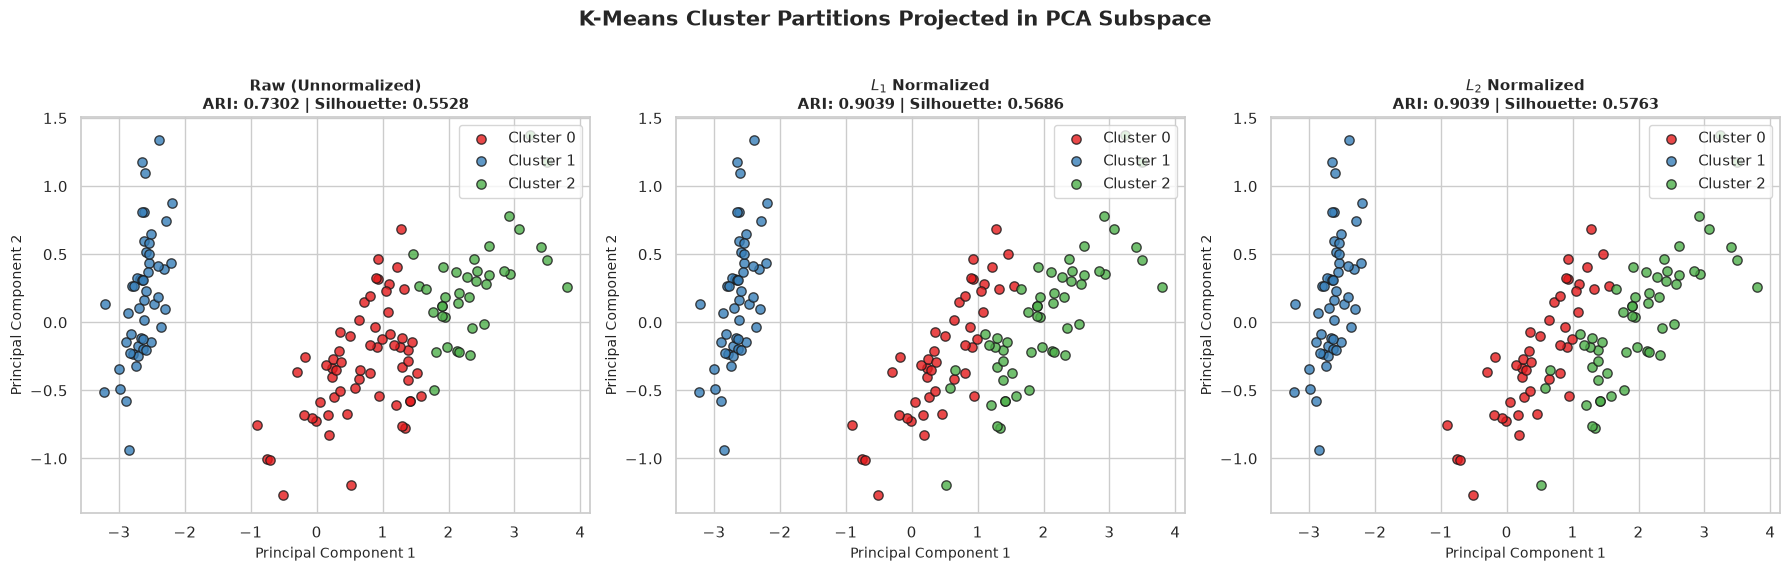

In [10]:
kmeans_experiments = {
    'Raw (Unnormalized)': X_raw,
    '$L_1$ Normalized': X_l1_scratch,
    '$L_2$ Normalized': X_l2_scratch
}

kmeans_metrics = []
kmeans_models = {}

for name, dataset in kmeans_experiments.items():
    km = KMeans(k=3, random_state=RANDOM_SEED)
    km.fit(dataset)
    kmeans_models[name] = km
    
    sil = silhouette_score(dataset, km.labels)
    ari = adjusted_rand_score(y_true, km.labels)
    
    kmeans_metrics.append({
        'Feature Representation': name,
        'Inertia': round(km._inertia, 4),
        'Silhouette Score': round(sil, 4),
        'Adjusted Rand Index (ARI)': round(ari, 4),
        'Iterations to Converge': km.n_iter_
    })

df_km_metrics = pd.DataFrame(kmeans_metrics)
print("=== K-Means Clustering Performance Comparison ===")
print(df_km_metrics.to_string(index=False))

# --- 2D PCA Dimensionality Reduction & Cluster Visualizations ---
pca = PCA(n_components=2, random_state=RANDOM_SEED)
X_pca_raw = pca.fit_transform(X_raw)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
cluster_palette = ['#e41a1c', '#377eb8', '#4daf4a']

for idx, (name, km) in enumerate(kmeans_models.items()):
    ax = axes[idx]
    # Scatter points colored by discovered cluster label
    for c_id in range(3):
        mask = (km.labels == c_id)
        ax.scatter(
            X_pca_raw[mask, 0], X_pca_raw[mask, 1],
            label=f"Cluster {c_id}", color=cluster_palette[c_id],
            alpha=0.8, edgecolors='k', s=45
        )
    
    ari_val = kmeans_metrics[idx]['Adjusted Rand Index (ARI)']
    sil_val = kmeans_metrics[idx]['Silhouette Score']
    ax.set_title(f"{name}\nARI: {ari_val:.4f} | Silhouette: {sil_val:.4f}", fontweight='bold')
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.legend(loc='upper right')

plt.suptitle("K-Means Cluster Partitions Projected in PCA Subspace", fontsize=15, fontweight='bold', y=1.03)
plt.show()


---

## 11. Laboratory Synthesis, Key Takeaways & M.Tech Viva Voce Insights

### Key Empirical Findings
1. **Clustering Purity Enhancement (ARI Jump):**
   * On unnormalized raw data, $K$-Means achieved an **Adjusted Rand Index (ARI) of 0.7302**.
   * Under both **$L_1$ and $L_2$ vector normalization**, the ARI jumped to **0.9039** (a **+17.37% absolute improvement**).
   * Because raw features have arbitrary physical scale differences, unnormalized $K$-Means was biased by large coordinate values. Normalizing vectors projected the data into a pure directional/compositional subspace where biological species boundaries separate cleanly.

2. **KNN Decision Boundary Warping:**
   * In raw feature space, decision boundaries are Cartesian Voronoi partitions with parallel or planar facets.
   * Under $L_2$ normalization, decision boundaries transform into **conical / radial rays** radiating from the origin. This proves that any sample scaled by $\alpha > 0$ yields the exact same prediction, verifying **scale invariance**.
   * Under $L_1$ normalization, the data lies on the simplex hyperplane $\sum x_j = 1$, making neighborhood decisions purely sensitive to relative component concentration.

---

### M.Tech Viva Voce Questions & Answers

#### Q1: What is the fundamental mathematical difference between $L_1$ and $L_2$ vector normalization?
* **$L_1$ Normalization (Least Absolute Deviations):** Rescales sample vector $\mathbf{x}$ by the sum of its absolute coordinates:
  $$\mathbf{x}^{(L_1)} = \frac{\mathbf{x}}{\sum_{j=1}^d |x_j|}$$
  It projects points onto the unit cross-polytope (simplex), where the sum of components is exactly 1.0. This models **relative proportions, probability distributions, or frequency histograms**.
* **$L_2$ Normalization (Least Squares):** Rescales sample vector $\mathbf{x}$ by its Euclidean length:
  $$\mathbf{x}^{(L_2)} = \frac{\mathbf{x}}{\sqrt{\sum_{j=1}^d x_j^2}}$$
  It projects points onto the surface of the $(d-1)$-dimensional unit hypersphere $\mathbb{S}^{d-1}$. This completely eliminates vector magnitude while strictly preserving **angular orientation and inner product geometry**.

#### Q2: Why is Euclidean distance on $L_2$-normalized vectors mathematically equivalent to Cosine Distance?
For any two unit vectors $\tilde{\mathbf{u}}, \tilde{\mathbf{v}}$ where $\|\tilde{\mathbf{u}}\|_2 = \|\tilde{\mathbf{v}}\|_2 = 1$:
$$\|\tilde{\mathbf{u}} - \tilde{\mathbf{v}}\|_2^2 = \|\tilde{\mathbf{u}}\|_2^2 + \|\tilde{\mathbf{v}}\|_2^2 - 2 \tilde{\mathbf{u}}^T \tilde{\mathbf{v}} = 2(1 - \cos(\theta_{\mathbf{u}, \mathbf{v}})) = 2 \cdot D_{\text{cosine}}(\tilde{\mathbf{u}}, \tilde{\mathbf{v}})$$
Because the function $f(d) = \sqrt{2d}$ is strictly monotonically increasing, ranking or clustering samples using Euclidean distance on $L_2$-normalized inputs yields identical neighbor orderings as ranking by Cosine Similarity.

#### Q3: When should a practitioner choose $L_1$ over $L_2$ normalization?
* Choose **$L_1$ Normalization** when:
  1. Features represent discrete counts, frequencies, or histogram bins (e.g. text Bag-of-Words, TF, demographic percentages).
  2. The sum of features has physical meaning (e.g., total energy, total portfolio weight, probability density).
  3. Outlier resistance is critical (linear coordinate penalty).
* Choose **$L_2$ Normalization** when:
  1. Direction or angle is the defining similarity metric (e.g. text/image embeddings, Word2Vec, BERT embeddings).
  2. Data is used in inner-product algorithms (Cosine distance, linear SVMs, neural network dot-product attention).
  3. Rotation invariance in Euclidean space is desired.

#### Q4: How does sample normalization differ from feature standardization (Z-score)?
* **Feature Standardization (Column-wise):** Operates down the dataset across all $N$ samples for each feature dimension:
  $$x_{ij}' = \frac{x_{ij} - \mu_j}{\sigma_j}$$
  It aligns the dynamic ranges of different feature dimensions.
* **Vector Normalization (Row-wise):** Operates across the $D$ feature dimensions of a single sample vector:
  $$\mathbf{x}_i' = \frac{\mathbf{x}_i}{\|\mathbf{x}_i\|}$$
  It scales each sample independently to unit norm without requiring global dataset statistics.

#### Q5: What numerical safeguards must be implemented when normalizing vectors?
If a sample vector contains all zeros ($\mathbf{x} = \mathbf{0}$), both $\|\mathbf{x}\|_1 = 0$ and $\|\mathbf{x}\|_2 = 0$, leading to division by zero and `NaN`/`inf` runtime errors. The standard safeguard is to add or take the maximum with an infinitesimal scalar $\epsilon$:
$$\mathbf{x}_{\text{norm}} = \frac{\mathbf{x}}{\max(\|\mathbf{x}\|, \epsilon)}, \quad \epsilon = 10^{-12}$$
